# What Drives Salaries? US Job Postings

**Question:** which factors are linked to the salary offered in US job postings: experience level, location, work type, or remote work?

**Data:** about 124,000 LinkedIn job postings from 2023–2024, split across five files that share a `job_id`. Two of the files also carry "noise" columns with no useful content. See the README for where the data comes from.

**Approach**
1. Merge the five files on `job_id` and check that nothing is lost or duplicated
2. Clean the salaries: one figure per posting, converted to an annual amount, with impossible values removed
3. Compare median salaries across experience levels, locations, work types and remote status, always showing how many postings each figure is based on

Medians are used throughout, because salaries are right-skewed: a few very high salaries pull the mean up.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_columns', 30)
plt.style.use('seaborn-v0_8-whitegrid')
dollars = FuncFormatter(lambda x, _: f'${x/1000:,.0f}k')

---
## 1. Loading and merging the five files

In [2]:
# Column layout of the five files (headers only)
files = {
    'postings1.csv': pd.read_csv('data/postings1.csv', nrows=0),
    'postings2.csv': pd.read_csv('data/postings2.csv', nrows=0),
    'postings3.csv': pd.read_csv('data/postings3.csv', nrows=0),
    'postings4.csv': pd.read_csv('data/postings4.csv', nrows=0),
    'postings5.xlsx': pd.read_excel('data/postings5.xlsx', nrows=0),
}
for name, header in files.items():
    cols = header.columns.tolist()
    noise = sum(c.startswith(('Easter Egg', 'Unimportant Column')) for c in cols)
    useful = [c for c in cols if not c.startswith(('Easter Egg', 'Unimportant Column'))]
    print(f"{name:15} {len(cols):2} columns ({noise} noise) | {useful}")

postings1.csv   21 columns (18 noise) | ['job_id', 'company_name', 'title']
postings2.csv    3 columns (0 noise) | ['job_id', 'description', 'max_salary']
postings3.csv    7 columns (0 noise) | ['job_id', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary']
postings4.csv   18 columns (0 noise) | ['job_id', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type']
postings5.xlsx   5 columns (2 noise) | ['job_id', 'company_name', 'title']


**What's in each file**

- **postings3:** pay period, location, minimum and median salary. This is the base table.
- **postings2:** maximum salary and the full job description.
- **postings4:** work type, experience level, remote flag and number of applications.
- **postings5:** company name and job title, plus 2 noise columns.
- **postings1:** company name and job title again, plus 18 noise columns.

So postings2, 4 and 5 are joined onto postings3 by `job_id`. postings1 repeats information that postings5 already has, which the next cell checks before setting it aside.

In [3]:
# Load only the columns the analysis needs (skips the long description text and the noise columns)
salary_info = pd.read_csv('data/postings3.csv')
max_salary  = pd.read_csv('data/postings2.csv', usecols=['job_id', 'max_salary'])
details     = pd.read_csv('data/postings4.csv', usecols=['job_id', 'formatted_work_type', 'formatted_experience_level',
                                                         'remote_allowed', 'applies', 'currency', 'work_type'])
titles      = pd.read_excel('data/postings5.xlsx', usecols=['job_id', 'company_name', 'title'])

# postings1 repeats company_name and title; check it agrees with postings5 before ignoring it
titles_1 = pd.read_csv('data/postings1.csv', usecols=['job_id', 'company_name', 'title'])
check = titles.merge(titles_1, on='job_id', suffixes=('', '_1'))
print(f"postings1 vs postings5: same title in {(check['title'].fillna('') == check['title_1'].fillna('')).mean():.1%} of rows, "
      f"same company in {(check['company_name'].fillna('') == check['company_name_1'].fillna('')).mean():.1%}")

# Left joins on job_id, starting from the salary file
jobs = salary_info.copy()
for part in [max_salary, details, titles]:
    jobs = jobs.merge(part, on='job_id', how='left')

assert len(jobs) == len(salary_info), "a join duplicated rows"
assert jobs['job_id'].is_unique
print(f"\nMerged: {jobs.shape[0]:,} postings x {jobs.shape[1]} columns, no duplicate job IDs")
jobs.head()

postings1 vs postings5: same title in 99.0% of rows, same company in 99.1%

Merged: 123,849 postings x 16 columns, no duplicate job IDs


,job_id,pay_period,location,company_id,views,med_salary,min_salary,max_salary,formatted_work_type,applies,remote_allowed,formatted_experience_level,work_type,currency,company_name,title
0,921716,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,17.0,20.0,Full-time,2.0,NaN,NaN,FULL_TIME,USD,Corcoran Sawyer Smith,Marketing Coordinator
1,1829192,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,30.0,50.0,Full-time,NaN,NaN,NaN,FULL_TIME,USD,NaN,Mental Health Therapist/Counselor
2,10998357,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,45000.0,65000.0,Full-time,NaN,NaN,NaN,FULL_TIME,USD,The National Exemplar,Assitant Restaurant Manager
3,23221523,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,140000.0,175000.0,Full-time,NaN,NaN,NaN,FULL_TIME,USD,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...
4,35982263,YEARLY,"Burlington, IA",NaN,3.0,NaN,60000.0,80000.0,Full-time,NaN,NaN,NaN,FULL_TIME,USD,NaN,Service Technician


**Result:** postings1 and postings5 agree on about 99% of titles and companies, so postings5 is enough. After the joins, all 123,849 postings are still there, with no duplicated job IDs.

---
## 2. Cleaning the salaries

In [4]:
for col in ['min_salary', 'max_salary', 'med_salary', 'applies']:
    jobs[col] = pd.to_numeric(jobs[col], errors='coerce')

print("Currency:", jobs['currency'].value_counts(dropna=False).to_dict())
print("Pay period:", jobs['pay_period'].value_counts(dropna=False).to_dict())

has_salary = jobs[['min_salary', 'max_salary', 'med_salary']].notna().any(axis=1)
print(f"\nPostings with any salary figure: {has_salary.sum():,} of {len(jobs):,} ({has_salary.mean():.0%})")

Currency: {nan: 87776, 'USD': 36058, 'EUR': 6, 'CAD': 3, 'BBD': 2, 'AUD': 2, 'GBP': 2}
Pay period: {nan: 87776, 'YEARLY': 20628, 'HOURLY': 14741, 'MONTHLY': 518, 'WEEKLY': 177, 'BIWEEKLY': 9}

Postings with any salary figure: 36,073 of 123,849 (29%)


**Observations**

- Only **36,073 postings (29%)** include any salary figure. Everything below is based on those.
- Postings without a salary also have no currency or pay period, so dropping them removes those blanks too.
- Salaries are quoted per year, month, two weeks, week or hour, so they have to be put on a common annual basis.

In [5]:
steps = [('All postings', len(jobs))]

# 1. US dollars only (a missing currency always goes with a missing salary, so it is dropped in step 2)
salaries = jobs[jobs['currency'].eq('USD') | jobs['currency'].isna()]
steps.append(('USD (or no currency)', len(salaries)))

# 2. Keep postings with at least one salary figure
salaries = salaries.dropna(subset=['min_salary', 'max_salary', 'med_salary'], how='all').copy()
steps.append(('Has a salary figure', len(salaries)))

# 3. One salary per posting: the stated median, else the midpoint of the range, else whichever end is given
salaries['salary'] = (salaries['med_salary']
                      .fillna((salaries['min_salary'] + salaries['max_salary']) / 2)
                      .fillna(salaries['min_salary'])
                      .fillna(salaries['max_salary']))

# 4. Annualise. Hourly pay assumes 40 hours a week (2,080 hours a year): a full-time equivalent
periods_per_year = {'YEARLY': 1, 'MONTHLY': 12, 'BIWEEKLY': 26, 'WEEKLY': 52, 'HOURLY': 2080}
salaries['annual_salary'] = salaries['salary'] * salaries['pay_period'].map(periods_per_year)

# 5. Remove impossible values: below the full-time federal minimum wage ($7.25 x 2,080 = $15,080)
#    are entry errors (e.g. "140-160" for a $140k-160k role), and the top 1% are extreme
MIN_WAGE_ANNUAL = 7.25 * 2080
too_low = salaries['annual_salary'] < MIN_WAGE_ANNUAL
print(f"Below ${MIN_WAGE_ANNUAL:,.0f}: {too_low.sum()} postings, for example:")
print(salaries.loc[too_low, ['title', 'pay_period', 'min_salary', 'max_salary', 'annual_salary']].head(4).to_string())
salaries = salaries[~too_low]
steps.append((f'At least ${MIN_WAGE_ANNUAL:,.0f} a year', len(salaries)))

top_cut = salaries['annual_salary'].quantile(0.99)
salaries = salaries[salaries['annual_salary'] <= top_cut].copy()
steps.append((f'At most the 99th percentile (${top_cut:,.0f})', len(salaries)))

print()
print(pd.DataFrame(steps, columns=['Step', 'Postings left']).to_string(index=False))

Below $15,080: 461 postings, for example:
                                          title pay_period  min_salary  max_salary  annual_salary
9                                Worship Leader    MONTHLY         NaN         NaN         4200.0
143  Clinical Trainee / Pre-Liscneded Therapist     YEARLY         NaN         NaN        14000.0
266                  Principal Backend Engineer     YEARLY       200.0       225.0          212.5
308     Records Specialist & Academic Scheduler     YEARLY        45.0        50.0           47.5

                                  Step  Postings left
                          All postings         123849
                  USD (or no currency)         123834
                   Has a salary figure          36058
               At least $15,080 a year          35597
At most the 99th percentile ($301,636)          35241


**Result:** 35,241 postings remain.

- **461 postings fall below the full-time minimum wage.** They're mostly entry errors, like *"200–225"* for a principal engineer (clearly $200k–225k), or hourly rates labelled as yearly.
- **The top 1% are above $301,636** and are trimmed as extreme.
- **Hourly salaries are converted at 2,080 hours a year (40 hours a week).** For part-time and hourly roles, that gives a full-time-equivalent figure, not what the person actually earns in a year.

---
## 3. How salaries are distributed

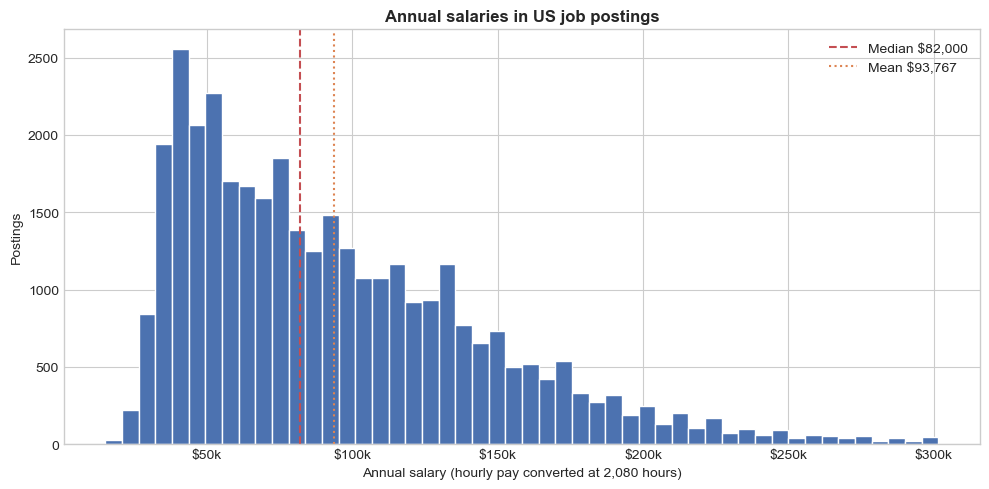

count     35241.0
mean      93767.0
std       51202.0
min       15080.0
10%       39520.0
25%       52000.0
50%       82000.0
75%      124800.0
90%      165000.0
max      301600.0
Name: annual_salary, dtype: float64


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(salaries['annual_salary'], bins=50, color='#4C72B0', edgecolor='white')
median, mean = salaries['annual_salary'].median(), salaries['annual_salary'].mean()
ax.axvline(median, color='#C44E52', linestyle='--', label=f'Median ${median:,.0f}')
ax.axvline(mean, color='#DD8452', linestyle=':', label=f'Mean ${mean:,.0f}')
ax.xaxis.set_major_formatter(dollars)
ax.set_title('Annual salaries in US job postings', fontweight='bold')
ax.set_xlabel('Annual salary (hourly pay converted at 2,080 hours)')
ax.set_ylabel('Postings')
ax.legend()
plt.tight_layout()
plt.show()

print(salaries['annual_salary'].describe(percentiles=[.1, .25, .5, .75, .9]).round(0))

**Observations**

- **Salaries are right-skewed.** The median is **$82,000**, while the mean is pulled up to **$93,767** by a long tail of high salaries.
- **Half of all postings offer between $52,000 and $124,800**, and 10% offer more than $165,000.
- **The biggest cluster is around $40,000–60,000,** where many hourly-paid roles sit.

Because of the skew, the rest of the analysis compares **medians**.

---
## 4. Experience level

                  median    mean   size
experience                             
Internship         48880   53161    365
Entry level        52500   64806   9000
Associate          74880   82225   3794
Mid-Senior level  107500  111268  12616
Director          165000  166093   1228
Executive         184500  177583    338
Not specified      77500   91402   7900


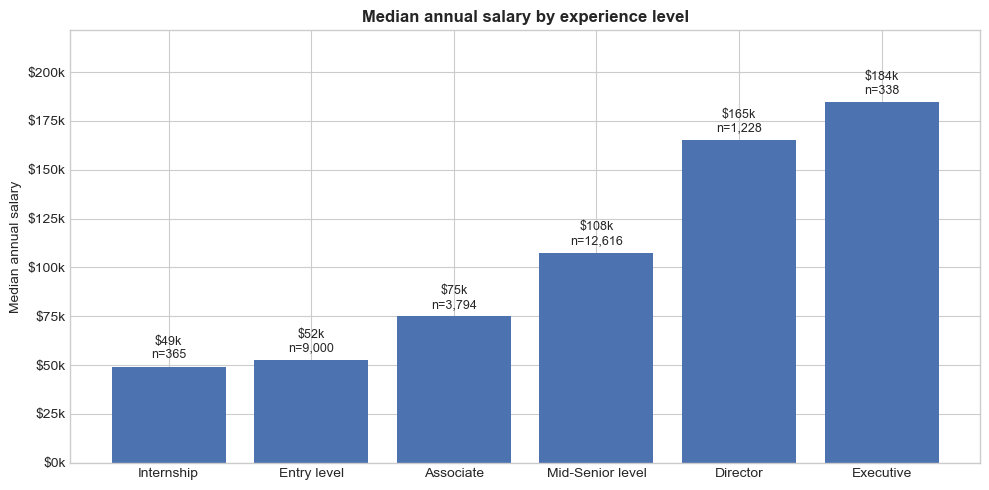

In [7]:
salaries['experience'] = salaries['formatted_experience_level'].fillna('Not specified')
order = ['Internship', 'Entry level', 'Associate', 'Mid-Senior level', 'Director', 'Executive']

by_exp = salaries.groupby('experience')['annual_salary'].agg(['median', 'mean', 'size']).reindex(order + ['Not specified'])
print(by_exp.round(0).astype(int).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(order, by_exp.loc[order, 'median'], color='#4C72B0')
for bar, (med, n) in zip(bars, by_exp.loc[order, ['median', 'size']].values):
    ax.text(bar.get_x() + bar.get_width() / 2, med + 3000, f'${med/1000:,.0f}k\nn={int(n):,}', ha='center', va='bottom', fontsize=9)
ax.yaxis.set_major_formatter(dollars)
ax.set_ylim(0, by_exp['median'].max() * 1.2)
ax.set_title('Median annual salary by experience level', fontweight='bold')
ax.set_ylabel('Median annual salary')
plt.tight_layout()
plt.show()

**Observations**

Median salary rises at every step up the career ladder:

| Level | Median | Postings |
|---|---|---|
| Internship | $48,880 | 365 |
| Entry level | $52,500 | 9,000 |
| Associate | $74,880 | 3,794 |
| Mid-Senior level | $107,500 | 12,616 |
| Director | $165,000 | 1,228 |
| Executive | $184,500 | 338 |

- The executive median is about **3.8 times** the internship median.
- The biggest jumps are from associate to mid-senior (+$32,620) and from mid-senior to director (+$57,500).
- 7,900 postings (22%) don't state a level. Their median ($77,500) sits in the middle, as expected for a mix of levels.

---
## 5. Location

In [8]:
# The trap: ranking locations by average salary with no minimum number of postings
naive = salaries.groupby('location')['annual_salary'].agg(['mean', 'size']).sort_values('mean', ascending=False)
print("Top 10 locations by average salary, any number of postings:")
print(naive.head(10).round(0).astype(int).to_string())

Top 10 locations by average salary, any number of postings:
                           mean  size
location                             
Black River Falls, WI    300000     1
Banning, CA              280500     1
Dix Hills, NY            277413     1
Wrangell, AK             264872     1
East Rockaway, NY        257500     1
Greater Burlington Area  254340     1
Portsmouth, OH           250705     1
Galesburg, IL            250000     1
Ipswich, MA              250000     1
Brewster, NY             238217     2


**This ranking is misleading.** Every location in this "top 10" has only 1 or 2 postings: a single $300,000 job in Black River Falls, Wisconsin tops the list. An average over one posting says nothing about a location. An earlier version of this analysis ranked locations this way, which is why it's corrected here.

The fix: only rank locations with **at least 100 postings**, and use the **median**.

Top 10 locations by median salary, at least 100 postings:
                                 median  size
location                                     
San Jose, CA                     140000   227
San Francisco Bay Area           140000   140
San Francisco, CA                130450   393
Seattle, WA                      125000   427
New York, United States          122500   253
United States                    114400  2520
California, United States        110257   184
New York City Metropolitan Area  110000   437
New York, NY                     110000  1473
Charlotte, NC                    107500   237

State found for 83% of postings; 31 states have at least 200 postings


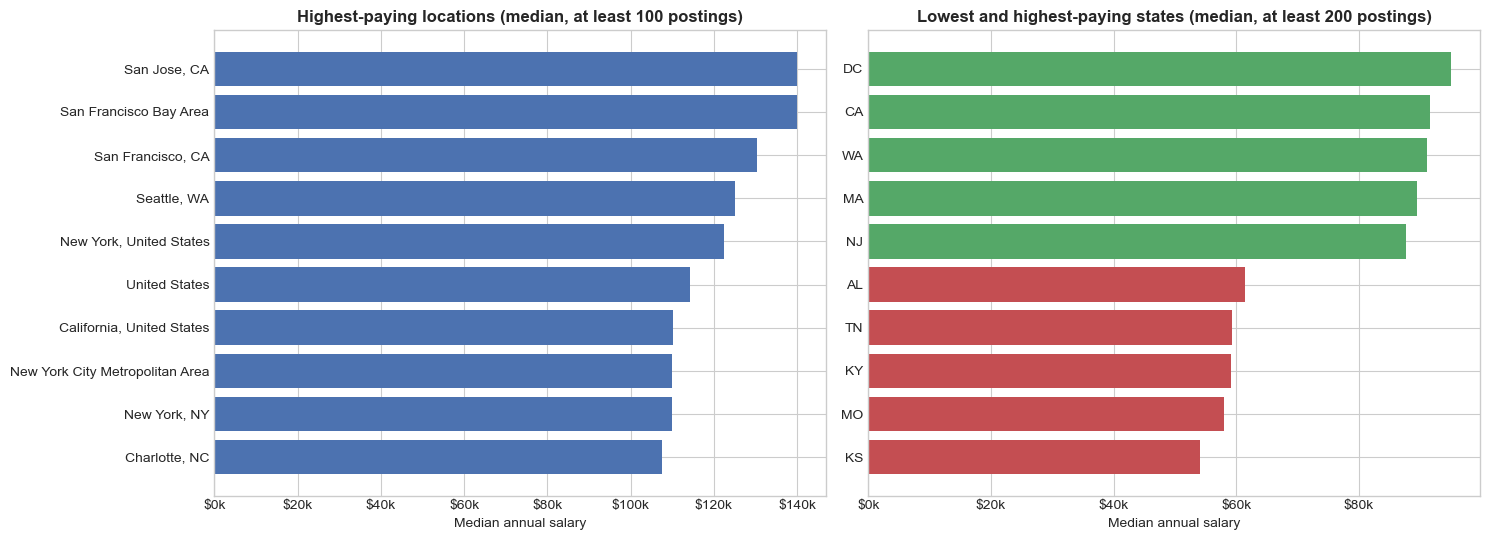

       median  size
state              
KS      54080   215
MO      58041   462
KY      59202   280
TN      59250   370
AL      61360   207
NJ      87750   865
MA      89440   859
WA      91039  1342
CA      91668  5664
DC      95000   294


In [9]:
MIN_POSTINGS = 100
by_loc = salaries.groupby('location')['annual_salary'].agg(['median', 'size'])
top_loc = by_loc[by_loc['size'] >= MIN_POSTINGS].sort_values('median', ascending=False).head(10)
print(f"Top 10 locations by median salary, at least {MIN_POSTINGS} postings:")
print(top_loc.round(0).astype(int).to_string())

# State from "City, ST" locations
salaries['state'] = salaries['location'].str.extract(r',\s*([A-Z]{2})$')[0]
by_state = salaries.groupby('state')['annual_salary'].agg(['median', 'size'])
by_state = by_state[by_state['size'] >= 200].sort_values('median')
print(f"\nState found for {salaries['state'].notna().mean():.0%} of postings; {len(by_state)} states have at least 200 postings")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(top_loc.index[::-1], top_loc['median'][::-1], color='#4C72B0')
axes[0].set_title(f'Highest-paying locations (median, at least {MIN_POSTINGS} postings)', fontweight='bold')
axes[0].xaxis.set_major_formatter(dollars)

shown = pd.concat([by_state.head(5), by_state.tail(5)])
colors = ['#C44E52'] * 5 + ['#55A868'] * 5
axes[1].barh(shown.index, shown['median'], color=colors)
axes[1].set_title('Lowest and highest-paying states (median, at least 200 postings)', fontweight='bold')
axes[1].xaxis.set_major_formatter(dollars)
for ax in axes:
    ax.set_xlabel('Median annual salary')
plt.tight_layout()
plt.show()

print(shown.round(0).astype(int).to_string())

**Observations**

- **Bay Area roles pay the most:** San Jose and the "San Francisco Bay Area" both have a median of $140,000, San Francisco itself $130,450. Seattle follows at $125,000, then New York at $110,000–122,500.
- **The location labels are messy.** "New York, NY", "New York City Metropolitan Area" and "New York, United States" are the same job market, and 2,520 postings give only "United States" as the location.
- **By state** (parsed from "City, ST" for 83% of postings, states with at least 200 postings): DC ($95,000), California ($91,668) and Washington ($91,039) pay the most. Kansas ($54,080) and Missouri ($58,041) pay the least. The highest-paying state's median is about **1.75 times** the lowest.

Location mixes several effects: cost of living, and which industries are based where (tech jobs cluster in the Bay Area and Seattle). This analysis shows the differences but can't separate those causes.

---
## 6. Work type and how pay is quoted

                      median  postings  share_hourly
formatted_work_type                                 
Part-time            42640.0      2250          0.87
Internship           45760.0       227          0.85
Other                57200.0       134          0.66
Temporary            57491.2       381          0.87
Full-time            84000.0     28540          0.31
Contract             98800.0      3706          0.90


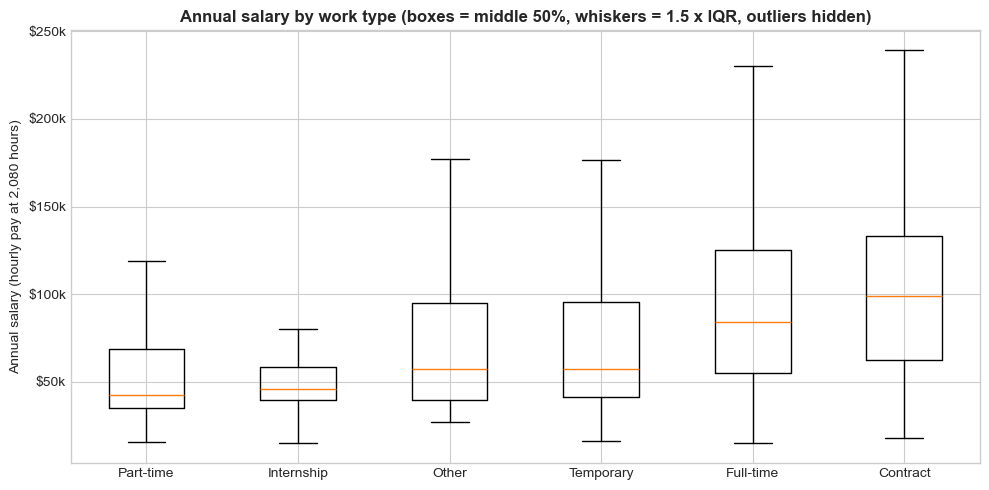


Median annual salary by pay period:
            median   size
pay_period               
BIWEEKLY     55484      3
HOURLY       52333  14678
MONTHLY      57336    493
WEEKLY      109148    177
YEARLY      102500  19890


In [10]:
by_work = salaries.groupby('formatted_work_type').agg(
    median=('annual_salary', 'median'),
    postings=('annual_salary', 'size'),
    share_hourly=('pay_period', lambda p: (p == 'HOURLY').mean()),
)
by_work = by_work[by_work['postings'] >= 100].sort_values('median')
print(by_work.round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
data = [salaries.loc[salaries['formatted_work_type'] == w, 'annual_salary'] for w in by_work.index]
ax.boxplot(data, tick_labels=by_work.index, showfliers=False)
ax.yaxis.set_major_formatter(dollars)
ax.set_title('Annual salary by work type (boxes = middle 50%, whiskers = 1.5 x IQR, outliers hidden)', fontweight='bold')
ax.set_ylabel('Annual salary (hourly pay at 2,080 hours)')
plt.tight_layout()
plt.show()

print("\nMedian annual salary by pay period:")
print(salaries.groupby('pay_period')['annual_salary'].agg(['median', 'size']).round(0).astype(int).to_string())

**Observations**

- **Contract roles have the highest median** ($98,800), above full-time ($84,000). **Part-time** ($42,640) and **internships** ($45,760) are the lowest.
- **These figures need care.** 87–90% of contract, part-time and temporary salaries are quoted per hour and converted at 40 hours a week, so they are full-time-equivalent rates. Part-time workers don't actually earn that much in a year. Contract rates also commonly come without benefits, which is one reason hourly contract rates run higher.
- **How pay is quoted matters a lot:** postings that quote an hourly rate have a median of $52,333, against $102,500 for those quoting a yearly salary. Hourly pay is more common for lower-paid roles.

---
## 7. Remote work

                median   size
remote                       
Not stated       77500  30543
Remote allowed  112500   4698

Median by experience level:
remote            Not stated  Remote allowed
experience                                  
Internship             48880           46800
Entry level            51636           77500
Associate              72800           80000
Mid-Senior level      103125          125000
Director              161164          176800
Executive             170000          213150

Postings:
remote            Not stated  Remote allowed
experience                                  
Internship               333              32
Entry level             8413             587
Associate               3318             476
Mid-Senior level       10425            2191
Director                 991             237
Executive                277              61


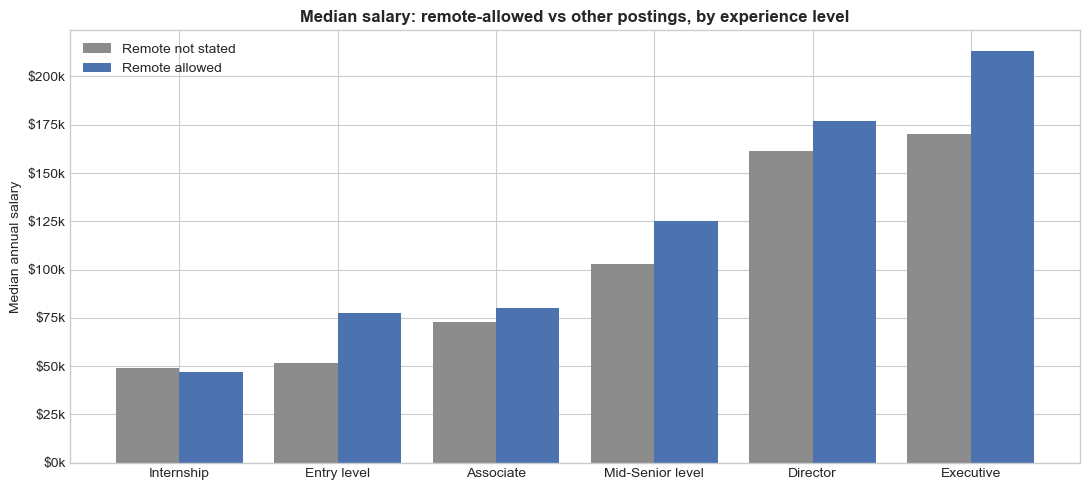

In [11]:
salaries['remote'] = np.where(salaries['remote_allowed'] == 1, 'Remote allowed', 'Not stated')
print(salaries.groupby('remote')['annual_salary'].agg(['median', 'size']).round(0).astype(int).to_string())

remote_exp = salaries.pivot_table(index='experience', columns='remote', values='annual_salary',
                                  aggfunc='median').reindex(order)
remote_n = salaries.pivot_table(index='experience', columns='remote', values='annual_salary',
                                aggfunc='size').reindex(order)
print("\nMedian by experience level:")
print(remote_exp.round(0).astype(int).to_string())
print("\nPostings:")
print(remote_n.to_string())

x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - 0.2, remote_exp['Not stated'], width=0.4, label='Remote not stated', color='#8C8C8C')
ax.bar(x + 0.2, remote_exp['Remote allowed'], width=0.4, label='Remote allowed', color='#4C72B0')
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.yaxis.set_major_formatter(dollars)
ax.set_title('Median salary: remote-allowed vs other postings, by experience level', fontweight='bold')
ax.set_ylabel('Median annual salary')
ax.legend()
plt.tight_layout()
plt.show()

**Observations**

- **Remote-allowed postings have a median of $112,500, against $77,500 for the rest** (4,698 vs 30,543 postings).
- **The gap holds within each experience level except internships:** +$25,864 at entry level, +$21,875 at mid-senior and +$43,150 at executive level. Remote internships pay slightly less, but there are only 32 of them.
- **This doesn't show that remote work causes higher pay.** Remote-friendly jobs are concentrated in higher-paying fields such as tech. Also, "not stated" isn't the same as on-site: some of those jobs may be remote too.

---
## 8. Conclusion

**Question:** which factors are linked to the salary offered in US job postings?

| Factor | Finding (medians) |
|---|---|
| **Experience level** | The strongest link: from $48,880 (internship) to $184,500 (executive), about 3.8 times |
| **Location** | Bay Area and Seattle highest ($125,000–140,000); the highest-paying state is about 1.75 times the lowest |
| **Remote work** | Remote-allowed postings pay $35,000 more overall, and more at every level except internships |
| **Work type** | Contract roles pay the highest full-time-equivalent rate; part-time and internships the lowest |

**Limitations**
- **Only 29% of postings state a salary**, and they may not be typical. For example, states with pay-transparency laws are likely over-represented.
- **Posted pay isn't actual pay,** and converting hourly rates at 40 hours a week overstates part-time earnings.
- **These are associations, not causes.** Experience, location, remote work and job field are tangled together. A regression model could estimate each factor's effect while holding the others fixed.
- **Location labels are inconsistent,** and the data covers a single snapshot (2023–2024).

**What I learned**
- **Always check group sizes before ranking groups.** A "top 10" based on one posting each is noise.
- **Use medians for skewed data like salaries.**
- **Check what a chart actually shows before writing conclusions about it.**